In [534]:
#!pip install category_encoders
#!pip install dython

In [535]:
import kagglehub
import pandas as pd
import io
from sklearn.preprocessing import LabelEncoder
RANDOM_STATE = 42

Загрузка датасета и запись информации в файл:

In [536]:
from sklearn.model_selection import train_test_split
path = kagglehub.dataset_download("uciml/horse-colic")

print("Path to dataset files:", path)
df_raw = pd.read_csv(path + '/horse.csv')
df = df_raw.copy()

Path to dataset files: /home/yana/.cache/kagglehub/datasets/uciml/horse-colic/versions/1


In [537]:

df['temp_of_extremities'] = df['temp_of_extremities'].map({'cold': 4, 'cool': 3, 'normal': 2, 'warm': 1})
df['peripheral_pulse'] = df['peripheral_pulse'].map({'absent': 4, 'reduced': 3, 'normal': 2, 'increased': 1})
to_numerical = df.select_dtypes(include = ['str', 'object'])
encoder = LabelEncoder()
for col in to_numerical:
    ohe_array = encoder.fit_transform(df[[col]])

    df_ohe = pd.DataFrame(ohe_array, columns = [col])

    df = pd.concat([df.drop(columns=[col]), df_ohe], axis=1)

df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   hospital_number        299 non-null    int64  
 1   rectal_temp            239 non-null    float64
 2   pulse                  275 non-null    float64
 3   respiratory_rate       241 non-null    float64
 4   temp_of_extremities    243 non-null    float64
 5   peripheral_pulse       230 non-null    float64
 6   nasogastric_reflux_ph  53 non-null     float64
 7   packed_cell_volume     270 non-null    float64
 8   total_protein          266 non-null    float64
 9   abdomo_protein         101 non-null    float64
 10  lesion_1               299 non-null    int64  
 11  lesion_2               299 non-null    int64  
 12  lesion_3               299 non-null    int64  
 13  surgery                299 non-null    int64  
 14  age                    299 non-null    int64  
 15  mucous_membrane  

/home/yana/Документы/iris/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/yana/Документы/iris/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/yana/Документы/iris/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/yana/Документы/iris/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_label.py:120: DataConversionWarning: A column-vector y 

,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,nasogastric_reflux_ph,packed_cell_volume,total_protein,abdomo_protein,...,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,rectal_exam_feces,abdomen,abdomo_appearance,outcome,surgical_lesion,cp_data
0,530101,38.5,66.0,28.0,3.0,3.0,NaN,45.0,8.4,NaN,...,0,2,3,3,1,0,3,0,0,0
1,534817,39.2,88.0,20.0,NaN,NaN,NaN,50.0,85.0,2.0,...,0,3,3,3,0,4,1,1,0,0
2,530334,38.3,40.0,24.0,2.0,2.0,NaN,33.0,6.7,NaN,...,2,1,3,3,3,3,3,2,0,1
3,5290409,39.1,164.0,84.0,4.0,2.0,5.0,48.0,7.2,5.3,...,0,2,0,0,1,5,2,0,1,1
4,530255,37.3,104.0,35.0,NaN,NaN,NaN,74.0,7.4,NaN,...,4,4,3,3,4,5,3,0,0,0


In [566]:
df_data = df.drop(columns = ['outcome'])
target = df['outcome']
X_train , X_test, y_train, y_test = train_test_split(df_data, target, random_state= RANDOM_STATE, test_size=0.2, stratify=target)

buffer = io.StringIO()

X_train.info(buf = buffer)

s = buffer.getvalue()

with open('df_info.txt', 'w', encoding='utf-8') as f:
    f.write(s)

X_train = X_train.drop(columns = ['cp_data', 'surgical_lesion', 'lesion_1', 'lesion_2', 'lesion_3','hospital_number'])
X_test = X_test.drop(columns = ['cp_data', 'surgical_lesion', 'lesion_1', 'lesion_2', 'lesion_3','hospital_number'])


In [539]:
def valid(series, low, high):
    return ~((series <= low) | (series >= high))

temp_mask = valid(df['rectal_temp'], 0, 45)
pulse_mask = valid(df['pulse'], 0, 300)
resp_mask = valid(df['respiratory_rate'], 0, 150)
ph_mask = valid(df['nasogastric_reflux_ph'], 0, 14)
volume_mask = valid(df['packed_cell_volume'], 0, 90)
df['total_protein'] = df['total_protein'] / 10
protein_mask = valid(df['total_protein'], 0, 15)
abdomo_mask = valid(df['abdomo_protein'], 0, 15)
mask = temp_mask & pulse_mask & resp_mask & ph_mask & volume_mask & protein_mask & abdomo_mask



df_removed = df[~mask].copy()
df_kept    = df[mask].copy()

print(f"Всего:    {len(df)}")
print(f"Оставлено: {len(df_kept)}")
print(f"Удалено:   {len(df_removed)}")

masks = {
    'temp':    temp_mask,
    'pulse':   pulse_mask,
    'resp':    resp_mask,
    'ph':      ph_mask,
    'pcv':     volume_mask,
    'tp':      protein_mask,
    'abdomo':  abdomo_mask,
}

total = len(df)
for name, m in masks.items():
    removed = (~m).sum()
    print(f"{name:8s} удалено {removed:4d} ({removed/total:.1%})")


Всего:    299
Оставлено: 299
Удалено:   0
temp     удалено    0 (0.0%)
pulse    удалено    0 (0.0%)
resp     удалено    0 (0.0%)
ph       удалено    0 (0.0%)
pcv      удалено    0 (0.0%)
tp       удалено    0 (0.0%)
abdomo   удалено    0 (0.0%)


In [540]:
df.head(15)

,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,nasogastric_reflux_ph,packed_cell_volume,total_protein,abdomo_protein,...,peristalsis,abdominal_distention,nasogastric_tube,nasogastric_reflux,rectal_exam_feces,abdomen,abdomo_appearance,outcome,surgical_lesion,cp_data
0,530101,38.5,66.0,28.0,3.0,3.0,NaN,45.0,0.84,NaN,...,0,2,3,3,1,0,3,0,0,0
1,534817,39.2,88.0,20.0,NaN,NaN,NaN,50.0,8.50,2.0,...,0,3,3,3,0,4,1,1,0,0
2,530334,38.3,40.0,24.0,2.0,2.0,NaN,33.0,0.67,NaN,...,2,1,3,3,3,3,3,2,0,1
3,5290409,39.1,164.0,84.0,4.0,2.0,5.0,48.0,0.72,5.3,...,0,2,0,0,1,5,2,0,1,1
4,530255,37.3,104.0,35.0,NaN,NaN,NaN,74.0,0.74,NaN,...,4,4,3,3,4,5,3,0,0,0
5,528355,NaN,NaN,NaN,1.0,2.0,NaN,NaN,NaN,NaN,...,2,3,2,2,1,2,3,2,0,0
6,526802,37.9,48.0,16.0,2.0,2.0,NaN,37.0,0.70,NaN,...,2,0,0,2,1,0,3,2,1,0
7,529607,NaN,60.0,NaN,3.0,NaN,NaN,44.0,0.83,NaN,...,0,3,2,2,1,1,3,0,1,0
8,530051,NaN,80.0,36.0,3.0,4.0,NaN,38.0,0.62,NaN,...,0,2,2,2,1,0,3,1,1,0
9,5299629,38.3,90.0,NaN,2.0,NaN,NaN,40.0,0.62,2.2,...,2,1,2,2,1,5,0,2,0,1


Пропуски в датасете и их тип

In [541]:
missing = df.isnull().sum()
print(missing)

hospital_number            0
rectal_temp               60
pulse                     24
respiratory_rate          58
temp_of_extremities       56
peripheral_pulse          69
nasogastric_reflux_ph    246
packed_cell_volume        29
total_protein             33
abdomo_protein           198
lesion_1                   0
lesion_2                   0
lesion_3                   0
surgery                    0
age                        0
mucous_membrane            0
capillary_refill_time      0
pain                       0
peristalsis                0
abdominal_distention       0
nasogastric_tube           0
nasogastric_reflux         0
rectal_exam_feces          0
abdomen                    0
abdomo_appearance          0
outcome                    0
surgical_lesion            0
cp_data                    0
dtype: int64


In [542]:
percents = missing/len(df)
print(percents)

hospital_number          0.000000
rectal_temp              0.200669
pulse                    0.080268
respiratory_rate         0.193980
temp_of_extremities      0.187291
peripheral_pulse         0.230769
nasogastric_reflux_ph    0.822742
packed_cell_volume       0.096990
total_protein            0.110368
abdomo_protein           0.662207
lesion_1                 0.000000
lesion_2                 0.000000
lesion_3                 0.000000
surgery                  0.000000
age                      0.000000
mucous_membrane          0.000000
capillary_refill_time    0.000000
pain                     0.000000
peristalsis              0.000000
abdominal_distention     0.000000
nasogastric_tube         0.000000
nasogastric_reflux       0.000000
rectal_exam_feces        0.000000
abdomen                  0.000000
abdomo_appearance        0.000000
outcome                  0.000000
surgical_lesion          0.000000
cp_data                  0.000000
dtype: float64


In [543]:
top = percents.nlargest(5)
print(top)

nasogastric_reflux_ph    0.822742
abdomo_protein           0.662207
peripheral_pulse         0.230769
rectal_temp              0.200669
respiratory_rate         0.193980
dtype: float64


Отсутствие признака nasogastric_reflux_ph незначительно влияет на распределение


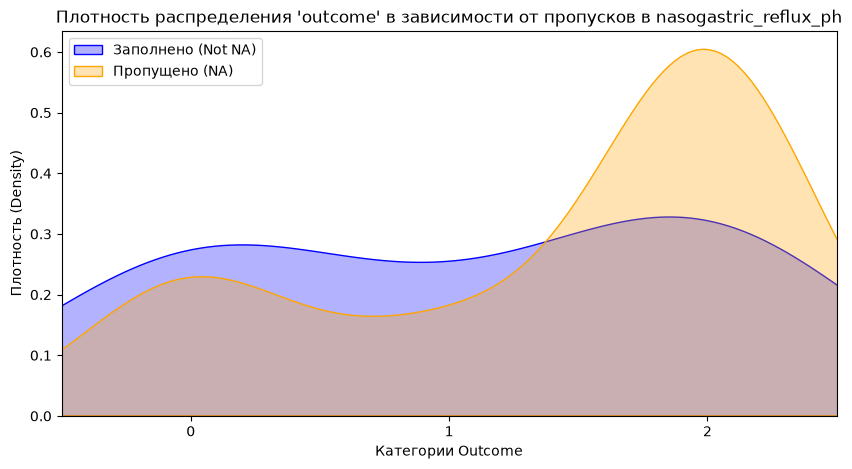

--------------------------------------------------
Отсутствие признака abdomo_protein незначительно влияет на распределение


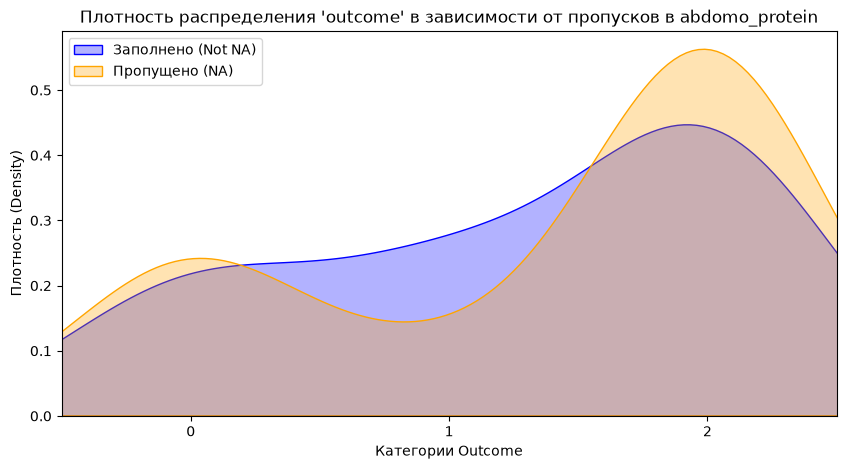

--------------------------------------------------
Отсутствие признака peripheral_pulse незначительно влияет на распределение


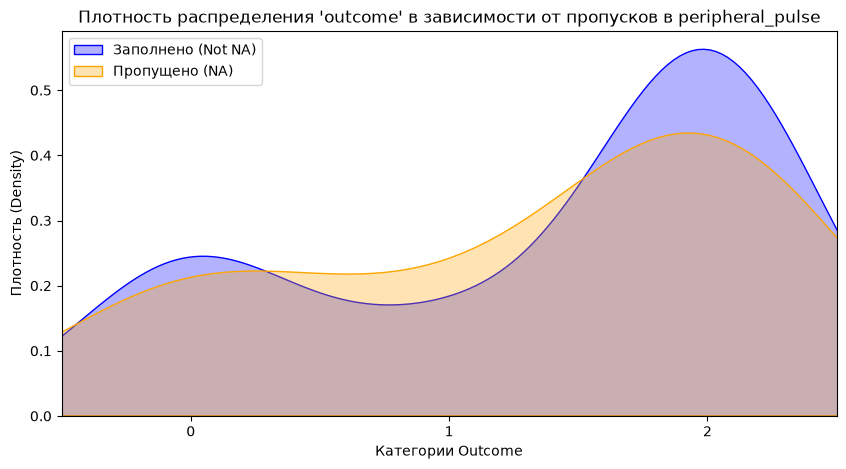

--------------------------------------------------
Отсутствие признака rectal_temp значимо влияет на распределение


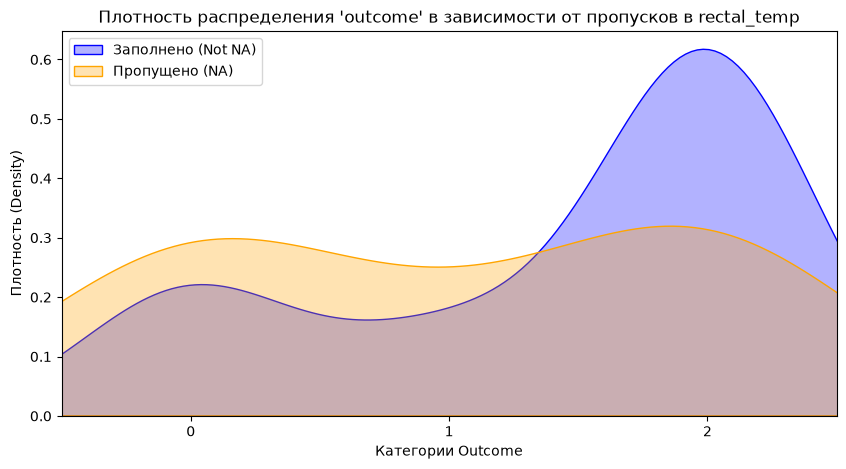

--------------------------------------------------
Отсутствие признака respiratory_rate незначительно влияет на распределение


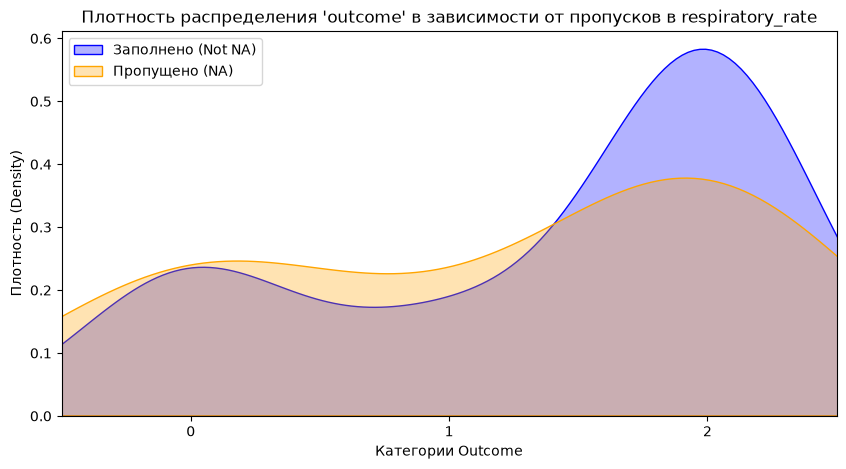

--------------------------------------------------


In [544]:
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

for col_name in top.index.to_list():

    df_temp = df[[col_name, 'outcome']].copy()
    df_temp['outcome_encoded'] = df_temp['outcome'].astype('category').cat.codes
    categories = df_temp['outcome'].astype('category').cat.categories
    target_when_filled = df_temp[df_temp[col_name].notna()]['outcome_encoded']
    target_when_missed = df_temp[df_temp[col_name].isna()]['outcome_encoded']

    statistic, p_value = stats.ks_2samp(target_when_filled, target_when_missed)

    if p_value < 0.05:
        print(f'Отсутствие признака {col_name} значимо влияет на распределение')
    else:
        print(f"Отсутствие признака {col_name} незначительно влияет на распределение")

    plt.figure(figsize=(10, 5))

    sns.kdeplot(
        data=target_when_filled, 
        label='Заполнено (Not NA)', 
        fill=True, 
        alpha=0.3, 
        color='blue', 
        bw_adjust=1.5
    )
    sns.kdeplot(
        data=target_when_missed, 
        label='Пропущено (NA)', 
        fill=True, 
        alpha=0.3, 
        color='orange', 
        bw_adjust=1.5
    )
    
    plt.title(f"Плотность распределения 'outcome' в зависимости от пропусков в {col_name}")

    plt.xticks(ticks=range(len(categories)), labels=categories)
    
    plt.xlabel('Категории Outcome')
    plt.ylabel('Плотность (Density)')
    plt.legend()

    plt.xlim(-0.5, len(categories) - 0.5)
    
    plt.show()
    print("-" * 50)

In [545]:
!pip install missingno


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


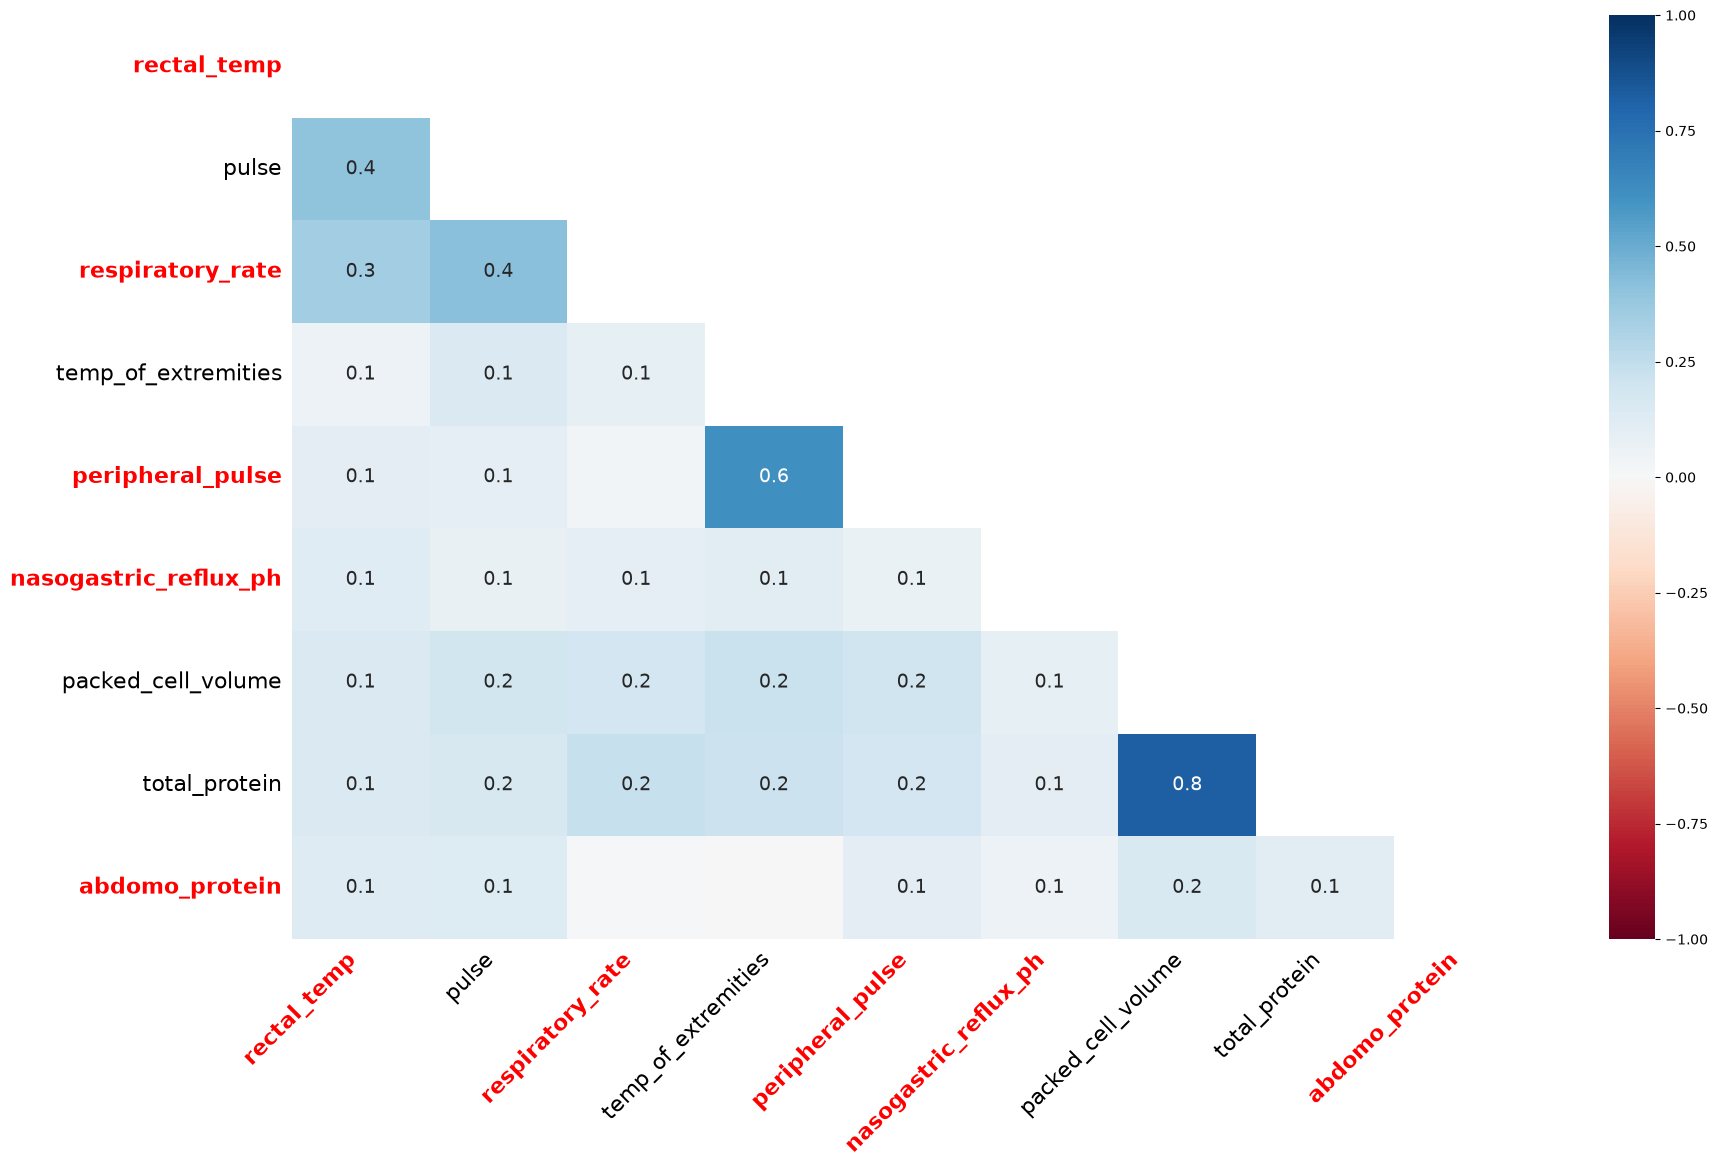

In [546]:
import missingno
import matplotlib.pyplot as plt
ax = missingno.heatmap(df)
for _ in ax.get_xticklabels():
    if _.get_text() in top:
        _.set_color('red')
        _.set_fontweight('bold')

for _ in ax.get_yticklabels():
    if _.get_text() in top:
        _.set_color('red')
        _.set_fontweight('bold')

plt.show()

In [547]:
!pip install --upgrade missingno matplotlib seaborn


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [548]:
mask_df = df[top.index].isnull()

for a in mask_df.columns:
    for b in mask_df.columns:
        if a == b:
            continue
        # P(B | A) — доля пропусков в B среди строк, где пропуск в A
        p_b_given_a = mask_df.loc[mask_df[a], b].mean()
        p_b = mask_df[b].mean()
        if p_b_given_a > p_b * 1.5 and mask_df[a].sum() > 10:
            print(f"P({b}|{a}) = {p_b_given_a:.2f} vs P({b}) = {p_b:.2f}")

P(respiratory_rate|rectal_temp) = 0.47 vs P(respiratory_rate) = 0.19
P(rectal_temp|respiratory_rate) = 0.48 vs P(rectal_temp) = 0.20


из heatmap можно сделать вывод, что reflux_ph 
- Не является случайным пропуском
- Не восстанавливается линейными методами из других признаков
Можно предположить MNAR


In [549]:
!pip install gower scikit-bio


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [556]:
import pandas as pd
from scipy.stats import chi2_contingency, fisher_exact

X_train['pH_is_missing'] = X_train['nasogastric_reflux_ph'].isna()

contingency_table = pd.crosstab(X_train['pH_is_missing'], y_train)
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

if p_value < 0.05:
    print('Связь статистически значима')
else:
    print('Связь незначима')

Связь незначима


Пропуски в колонке влияют на таргетную переменную. Стратегия: оставим строки с пропусками, введем новый индикатор наличия пропуска

In [564]:

X_train['pH_is_missing'] = X_train['nasogastric_reflux_ph'].isna().astype(int)
X_train['nasogastric_reflux_ph'] = X_train['nasogastric_reflux_ph'].fillna(-1)

X_test['pH_is_missing'] = X_test['nasogastric_reflux_ph'].isna().astype(int)
X_test['nasogastric_reflux_ph'] = X_test['nasogastric_reflux_ph'].fillna(-1)

для остальных колонок выберем стратегию заполнения медианой
todo: заполнение медианой

In [567]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)
X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index,
)

In [568]:


from scipy.stats import entropy
outcome = y_train
probabilities = outcome.value_counts(normalize=True)
target_entropy = entropy(probabilities, base = 2)
print(target_entropy)

1.3571464405885942


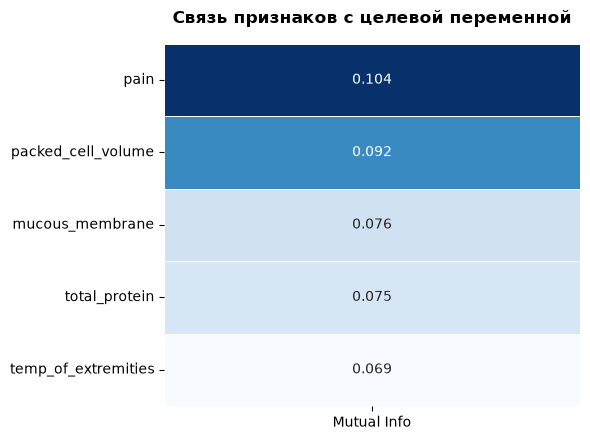

In [569]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression

target_col = "outcome"
labeled_features = df_raw.select_dtypes(include = ['str']).columns.tolist() # Ваши закодированные колонки

X = X_train.copy()
y = y_train.copy()

for col in X.columns:
    if X[col].isnull().any():
        if X[col].isnull().all():
            X[col] = X[col].fillna(0 if col not in labeled_features else "missing")
            continue

        if col in labeled_features or X[col].dtype == "object":
            most_frequent = X[col].mode().iloc[0]
            X[col] = X[col].fillna(most_frequent)
        else:
            median_val = X[col].median()
            X[col] = X[col].fillna(median_val)



discrete_mask = [col in labeled_features for col in X.columns]

if y.dtype == "object" or y.nunique() < 15:
    mi_scores = mutual_info_classif(X, y, random_state=RANDOM_STATE, discrete_features=discrete_mask)/target_entropy
    title_suffix = "(Классификация)"
else:
    mi_scores = mutual_info_regression(X, y, random_state=RANDOM_STATE, discrete_features=discrete_mask)/target_entropy
    title_suffix = "(Регрессия)"

mi_df = pd.DataFrame({"Mutual Info": mi_scores}, index=X.columns)
mi_df = mi_df.sort_values(by="Mutual Info", ascending=False)
mi_filtered = mi_df[mi_df["Mutual Info"] >= 0.3]

if mi_filtered.empty:
    mi_filtered = mi_df.head(5)

plt.figure(figsize=(6, len(mi_filtered) * 0.5 + 2))
sns.heatmap(
    mi_filtered,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    linewidths=0.5,
    cbar=False,
)
plt.title(label = 'Связь признаков с целевой переменной',
    fontsize=12,
    pad=15,
    fontweight="bold",
)
plt.tight_layout()
plt.show()


todo: посмотреть дисбаланс, параметры, уменьшить размерность

In [555]:
ratios = y_train.value_counts(normalize=True).round(3)
print(ratios)

outcome
2    0.594
0    0.259
1    0.146
Name: proportion, dtype: float64


Нужно переделать - сначала заполнить пропуски, потом добавить сплит, только на трэйн-сплите смотреть mi, дисбаланс и другие метрики.
Остается посмотреть параметры распределений и уменьшить размерность.

Топ-5 информативных признаков: ['pain', 'packed_cell_volume', 'mucous_membrane', 'total_protein', 'temp_of_extremities']
                     Mutual Info
pain                    0.103878
packed_cell_volume      0.091797
mucous_membrane         0.076121
total_protein           0.074764
temp_of_extremities     0.069103


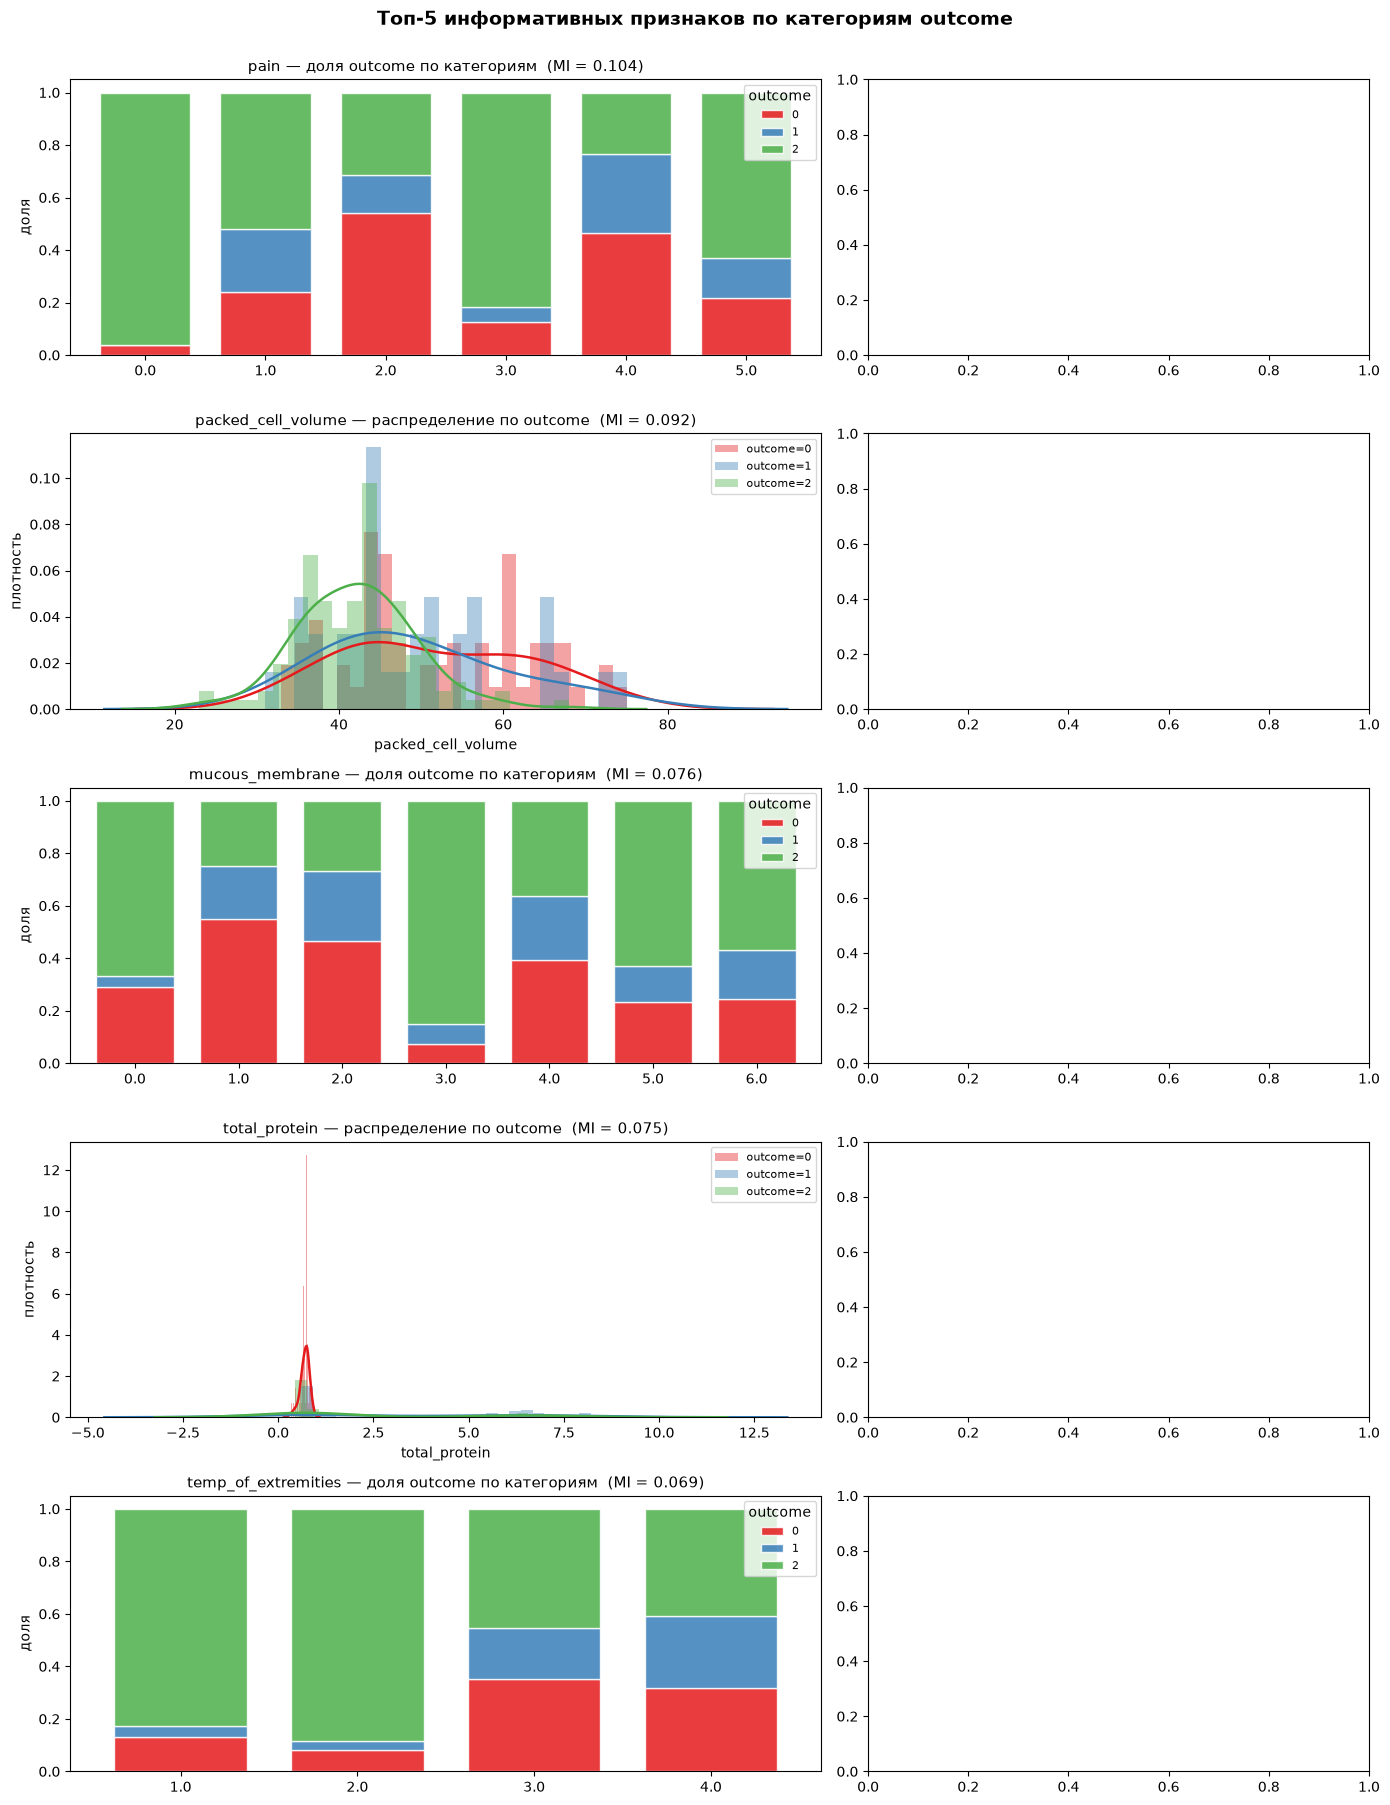

In [576]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# 1. Топ-5 признаков по Mutual Information
top5_features = mi_df.head(5).index.tolist()
print("Топ-5 информативных признаков:", top5_features)
print(mi_df.head(5))

# 2. Собираем DataFrame: X_train уже импутирован, добавляем к нему target
df_viz = X_train.copy()
df_viz['outcome'] = y_train.values

outcomes = sorted(df_viz['outcome'].unique())
palette = dict(zip(outcomes, sns.color_palette('Set1', n_colors=len(outcomes))))

# 3. Категориальные признаки (те, что изначально были строками)
cat_features = df_raw.select_dtypes(include=['str', 'object']).columns.tolist()

# 4. Рисуем: слева — распределение по outcome, справа — violin
n = len(top5_features)
fig, axes = plt.subplots(
    n, 2,
    figsize=(14, 3.6 * n),
    gridspec_kw={'width_ratios': [3, 2]},
)

for i, col in enumerate(top5_features):
    ax_dist, ax_violin = axes[i]
    mi_val = mi_df.loc[col, 'Mutual Info']
    n_unique = df_viz[col].nunique()

    if col in cat_features or n_unique <= 6:
        # --- Категориальный: stacked bar с долями outcome ---
        ct = pd.crosstab(df_viz[col], df_viz['outcome'], normalize='index')
        ct.plot(
            kind='bar', stacked=True, ax=ax_dist,
            color=[palette[o] for o in ct.columns],
            alpha=0.85, edgecolor='white', width=0.75,
        )
        ax_dist.set_title(f'{col} — доля outcome по категориям  (MI = {mi_val:.3f})',
                          fontsize=11)
        ax_dist.set_ylabel('доля')
        ax_dist.set_xlabel('')
        ax_dist.legend(title='outcome', fontsize=8, loc='upper right')
        ax_dist.tick_params(axis='x', rotation=0)
    else:
        # --- Числовой: гистограмма + KDE на каждый outcome ---
        for out_val in outcomes:
            subset = df_viz.loc[df_viz['outcome'] == out_val, col]
            ax_dist.hist(
                subset, bins=25, alpha=0.4, density=True,
                color=palette[out_val], label=f'outcome={out_val}',
            )
            sns.kdeplot(
                subset, ax=ax_dist, color=palette[out_val],
                linewidth=1.8, bw_adjust=1.2,
            )
        ax_dist.set_title(f'{col} — распределение по outcome  (MI = {mi_val:.3f})',
                          fontsize=11)
        ax_dist.set_ylabel('плотность')
        ax_dist.legend(fontsize=8)


plt.suptitle('Топ-5 информативных признаков по категориям outcome',
             fontsize=14, fontweight='bold', y=1.0)
plt.tight_layout()
plt.show()